In [1]:
# data and numbers
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.pylab as pylab
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
%matplotlib inline
mpl.rcParams['figure.figsize'] = (12,8)
mpl.rcParams['font.size'] = 12
mpl.rcParams['figure.dpi'] = 80
import seaborn as sns
sns.set_style("darkgrid")
mpl.style.use('ggplot')

import gc

# Weather Dataset


* <code>timestamp</code>: date and time in the format YYYY-MM-DD hh:mm:ss. Local timezone.
* <code>site_id</code>: animal-code-name for the site.
* <code>airTemperature</code>: The temperature of the air in degrees Celsius (ºC).
* <code>cloudCoverage</code>: Portion of the sky covered in clouds, in [oktas](https://en.wikipedia.org/wiki/Okta).
* <code>dewTemperature</code>: The dew point (the temperature to which a given parcel of air must be cooled at constant pressure and water vapor content in order for saturation to occur) in degrees Celsius (ºC).
* <code>precipDepth1HR</code>: The depth of liquid precipitation that is measured over a one hour accumulation period (mm).
* <code>precipDepth6HR</code>: The depth of liquid precipitation that is measured over a six hour accumulation period (mm).
* <code>seaLvlPressure</code>: The air pressure relative to Mean Sea Level (MSL) (mbar or hPa).
* <code>windDirection</code>: The angle, measured in a clockwise direction, between true north and the direction from which the wind is blowing (degrees).
* <code>windSpeed</code>: The rate of horizontal travel of air past a fixed point (m/s). 

In [3]:
path = "../data/weather/"
weather = pd.read_csv(path + "weather.csv")
weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 331166 entries, 0 to 331165
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   timestamp       331166 non-null  object 
 1   site_id         331166 non-null  object 
 2   airTemperature  331038 non-null  float64
 3   cloudCoverage   160179 non-null  float64
 4   dewTemperature  330838 non-null  float64
 5   precipDepth1HR  197980 non-null  float64
 6   precipDepth6HR  18162 non-null   float64
 7   seaLvlPressure  309542 non-null  float64
 8   windDirection   318161 non-null  float64
 9   windSpeed       330592 non-null  float64
dtypes: float64(8), object(2)
memory usage: 25.3+ MB


timestamp          0.000000
site_id            0.000000
airTemperature     0.038651
cloudCoverage     51.631810
dewTemperature     0.099044
precipDepth1HR    40.217293
precipDepth6HR    94.515741
seaLvlPressure     6.529656
windDirection      3.927034
windSpeed          0.173327
dtype: float64


<Axes: >

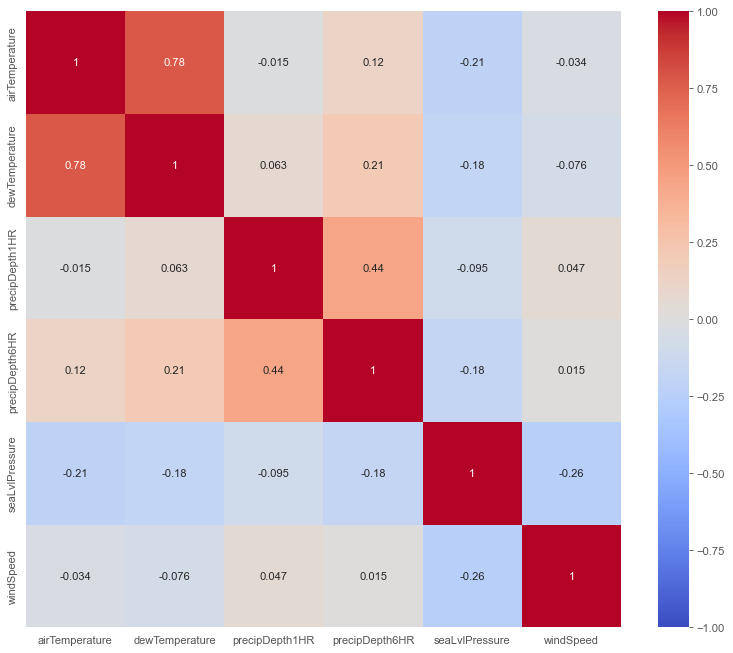

In [5]:
# Percentage of missing values in each feature
print(weather.isna().sum()/len(weather)*100)
# Drop categorical features
weather1 = weather.drop(["timestamp","site_id","cloudCoverage","windDirection"], axis=1)
# Plot correlation heatmap
f = plt.figure(1, figsize=(12,10))
sns.heatmap(weather1.corr(), cmap="coolwarm", vmin=-1, vmax=1, annot=True)

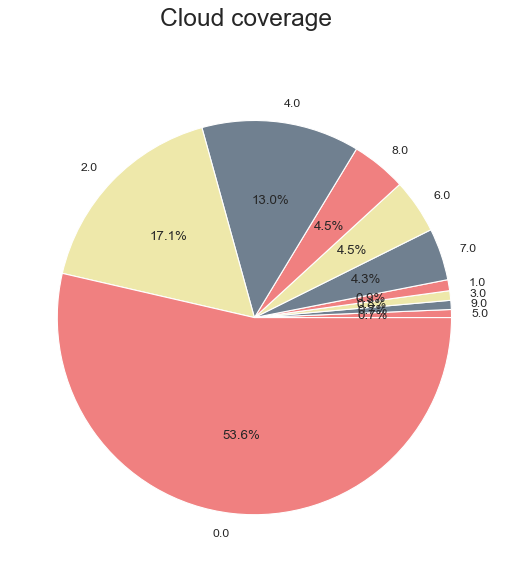

In [21]:
colors = ["lightcoral","slategray", "palegoldenrod"]

# Make square figures and axes
f = plt.figure(1, figsize=(8,8))

# Temporal dataframe with cloud cover counts
temp1 = pd.DataFrame(weather.groupby("cloudCoverage").count().timestamp).rename(columns={"timestamp":"Count"})
temp_labels1 = temp1["Count"].sort_values().index
temp_counts1 = temp1["Count"].sort_values()
# Cloud cover pie chart
g4 = plt.pie(temp_counts1, labels=temp_labels1, autopct='%1.1f%%', shadow=False, colors=colors)

# Figure title
plt.suptitle('Cloud coverage', fontsize=22)

plt.show()

Text(0.5, 0.98, 'Wind Direction')

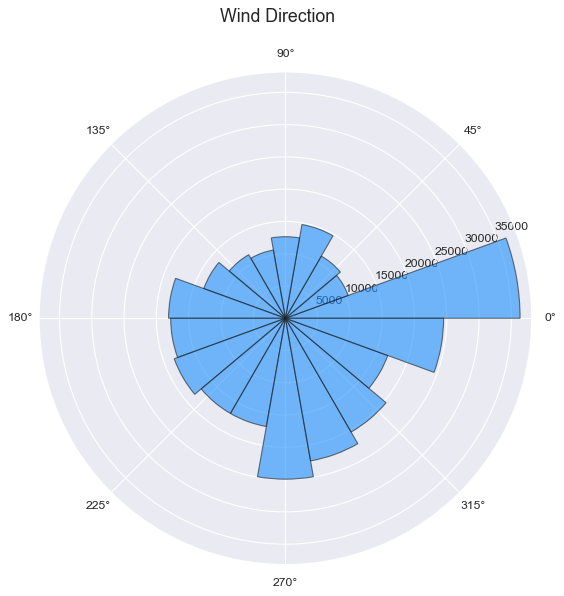

In [8]:
sns.set(rc={'figure.figsize':(8,8)})

# Wind direction (radial plot)
degrees = weather["windDirection"]
radians = np.deg2rad(weather["windDirection"])
bin_size = 20
a , b = np.histogram(degrees, bins=np.arange(0, 360+bin_size, bin_size))
centers = np.deg2rad(np.ediff1d(b)//2 + b[:-1])
# Wind direction plot
plt.subplot(aspect=2, projection='polar')
g4 = plt.bar(centers, a, width=np.deg2rad(bin_size), bottom=0.0, color="dodgerblue", alpha=0.6, edgecolor='k')
# Figure title
plt.suptitle('Wind Direction', fontsize=16)

/var/folders/rn/tvl6wp8n0tl7g97k8yjmlkpr0000gn/T/ipykernel_38882/3946477207.py:25: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  g1 = sns.distplot(weather["airTemperature"].dropna(), ax=ax1, color=color)
/var/folders/rn/tvl6wp8n0tl7g97k8yjmlkpr0000gn/T/ipykernel_38882/3946477207.py:31: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750

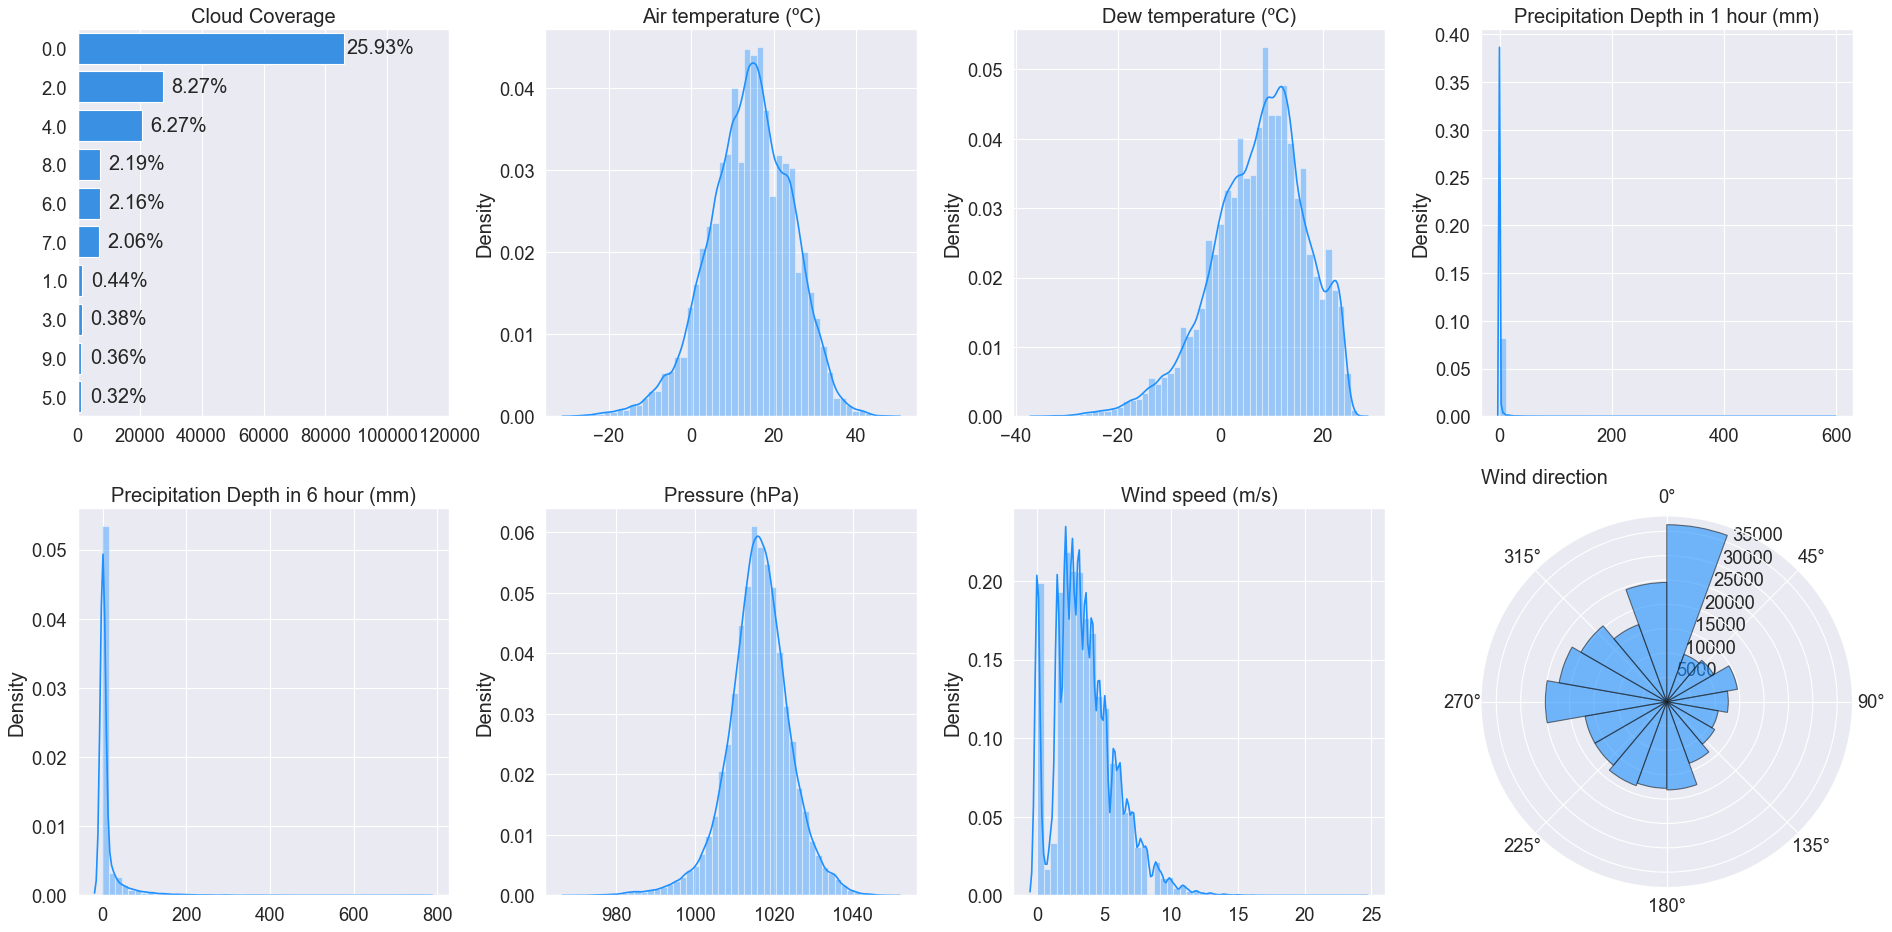

In [9]:
sns.set(rc={'figure.figsize':(24,12)})
sns.set(font_scale = 1.5)
f, axes = plt.subplots(2, 4)
axes = axes.flatten()

color = "dodgerblue"

# Cloud Coverage countplot in decreasing order
ax0 = axes[0]
g0 = sns.countplot(data=weather, y="cloudCoverage", color= color, orient="h", ax=ax0, order = weather['cloudCoverage'].value_counts().index)
ax0.title.set_text('Cloud Coverage')
ax0.set(ylabel="", xlabel="", xlim=(0,120000))
# adds percentage    
total = float(len(weather)) # number of rows
for p in g0.patches:
    width = p.get_width()
    g0.text(width + 12000,
            p.get_y() + p.get_height()/1.5,
            '{:1.2%}'.format(width/total),
            ha="center") 
    

# "airTemperature" histogram
ax1 = axes[1]
g1 = sns.distplot(weather["airTemperature"].dropna(), ax=ax1, color=color)
ax1.set_title('Air temperature (ºC)')
ax1.set(xlabel="")

# "dewTemperature" histogram
ax2 = axes[2]
g2 = sns.distplot(weather["dewTemperature"].dropna(), ax=ax2, color=color)
ax2.set_title('Dew temperature (ºC)')
ax2.set(xlabel="")

# "precipDepth1HR" histogram
ax3 = axes[3]
g3 = sns.distplot(weather["precipDepth1HR"].dropna(), ax=ax3, color=color, kde_kws={'bw':0.1})
ax3.set_title('Precipitation Depth in 1 hour (mm)')
ax3.set(xlabel="")

# "precipDepth6HR" histogram
ax4 = axes[4]
g4 = sns.distplot(weather["precipDepth6HR"].dropna(), ax=ax4, color=color)
ax4.set_title('Precipitation Depth in 6 hour (mm)')
ax4.set(xlabel="")

# "seaLvlPressure" histogram
ax5 = axes[5]
g5 = sns.distplot(weather["seaLvlPressure"].dropna(), ax=ax5, color=color)
ax5.set_title('Pressure (hPa)')
ax5.set(xlabel="")

# "windSpeed" histogram
ax6 = axes[6]
g6 = sns.distplot(weather["windSpeed"].dropna(), ax=ax6, color=color)
ax6.set_title('Wind speed (m/s)')
ax6.set(xlabel="")

# "windDirection" polar histogram
degrees = weather["windDirection"]
radians = np.deg2rad(weather["windDirection"])
bin_size = 20
a , b = np.histogram(degrees, bins=np.arange(0, 360+bin_size, bin_size))
centers = np.deg2rad(np.ediff1d(b)//2 + b[:-1])
ax7 = f.add_subplot(248, projection='polar')
ax7.set_theta_zero_location("N")
ax7.set_theta_direction("clockwise")
g7 = plt.bar(centers, a, width=np.deg2rad(bin_size), bottom=0.0, color=color, alpha=0.6, edgecolor='k')
ax7.set_title('Wind direction', pad=5, loc="left")
     
# Remove empty axes
f.delaxes(axes[7])

plt.tight_layout()
plt.show()

# Monthly Analysis

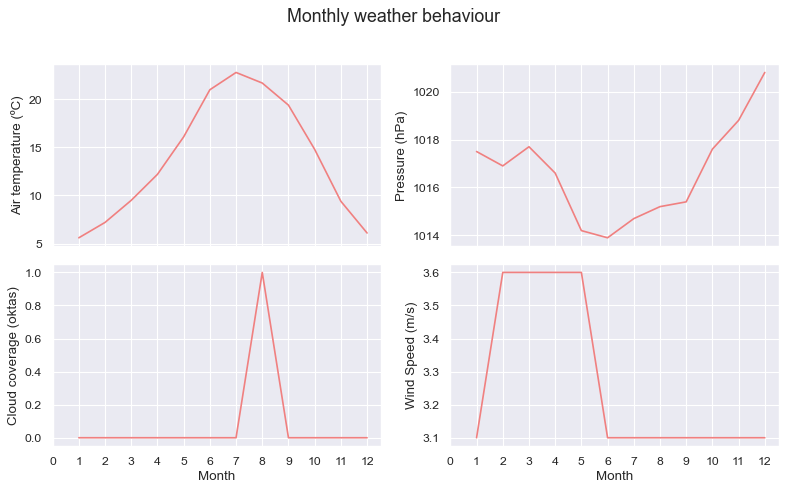

In [15]:
# datetime indexes
times = pd.DatetimeIndex(weather.timestamp)
# Median for each month
sns.set(rc={"figure.figsize": (10, 6)})
# sns.set(font_scale = 1)
f, axes = plt.subplots(2, 2, sharex=True)
axes = axes.flatten()
color = colors[0]

# Creates a temporal dataframe grouped by month of the year
temp = (
    weather.groupby(times.month)[
        [
            "airTemperature",
            "cloudCoverage",
            "seaLvlPressure",
            "windSpeed"
        ]
    ]
    .median()
    .reset_index()
)

# plots
ax0 = axes[0]
g0 = sns.lineplot(data=temp, x="timestamp", y="airTemperature", ax=ax0, color = color)
#ax1.title.set_text("Apparent temperature")
ax0.set(ylabel="Air temperature (ºC)")

ax1 = axes[1]
g1 = sns.lineplot(data=temp, x="timestamp", y="seaLvlPressure", ax=ax1, color = color)
#ax1.title.set_text("Pressure")
ax1.set(ylabel="Pressure (hPa)")

ax2 = axes[2]
g2 = sns.lineplot(data=temp, x="timestamp", y="cloudCoverage", ax=ax2, color = color)
#ax2.title.set_text("Cloud coverage")
ax2.set(ylabel="Cloud coverage (oktas)")

ax3 = axes[3]
g3 = sns.lineplot(data=temp, x="timestamp", y="windSpeed", ax=ax3, color = color)
#ax3.title.set_text("Relative humidity")
ax3.set(ylabel="Wind Speed (m/s)")

# Customize axes
for ax in axes:
    ax.title.set_size(15)  # fontsize
    ax.set(xlabel="Month")  # X label
    ax.set_xticks(range(13))  # X range

# Figure title
plt.suptitle('Monthly weather behaviour', y=1.02, fontsize=16)

f.tight_layout()

Text(0.5, 1.02, 'Monthly air temperature behaviour by site')

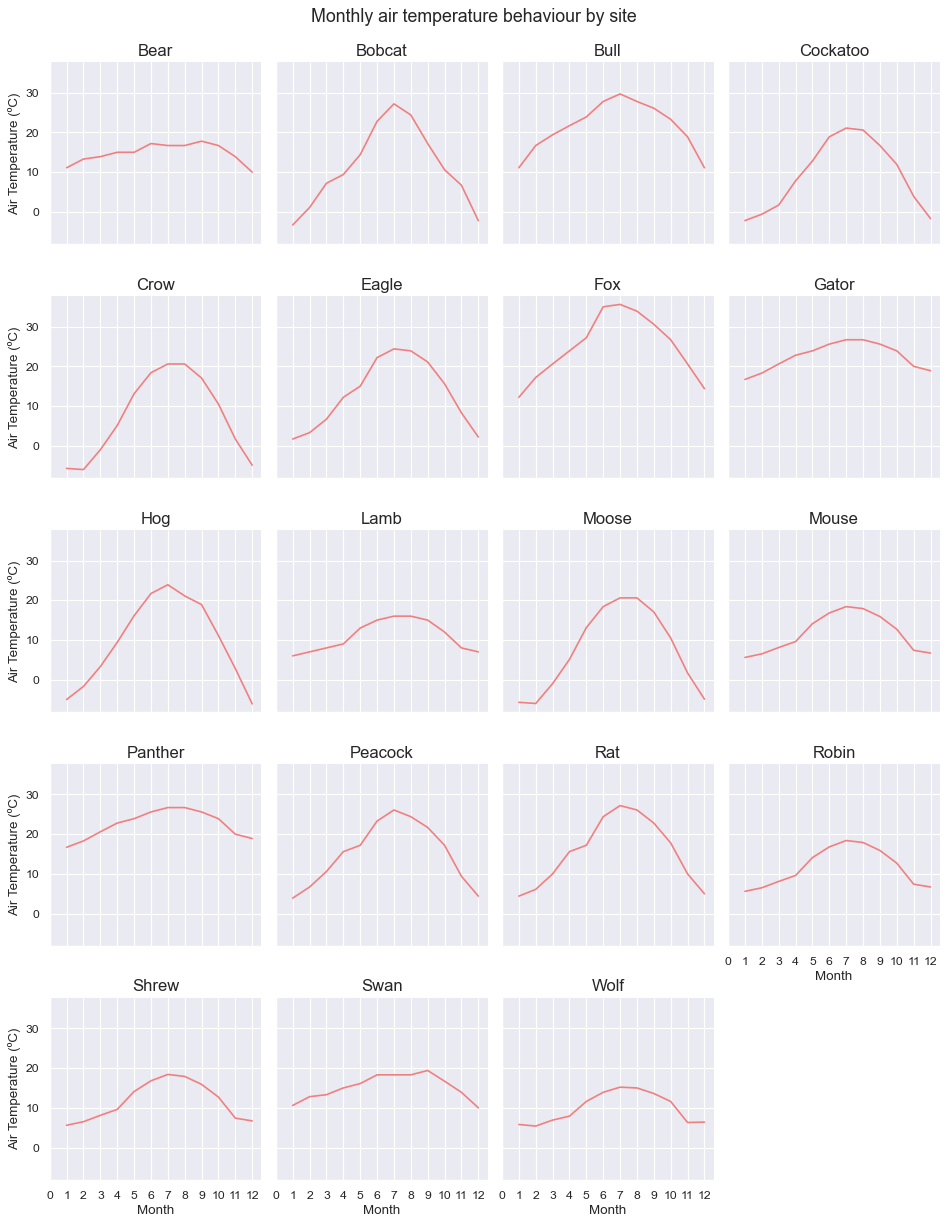

In [16]:
# Creates a temporal dataframe grouped by site and month
temp = pd.DataFrame(
    weather.groupby(["site_id", times.month])
    ["airTemperature"]
    .median()
    .reset_index()
)
# All the plots in a grid
g = sns.FacetGrid(temp, col="site_id", col_wrap=4)
g.map(plt.plot, "timestamp", "airTemperature", color=colors[0])
# Title of each plot
g.set_titles("{col_name}", size=15)
# Axis labels
g.set_axis_labels(x_var="Month", y_var="Air Temperature (ºC)")
g.set(xticks=range(13))
# Figure title
plt.suptitle('Monthly air temperature behaviour by site', y=1.02, fontsize=16)

We see that due to the varying geospatial distribution of the sites, the air temperature distribution varies across the set of sites.

Text(0.5, 1.02, 'Monthly pressure behaviour by site')

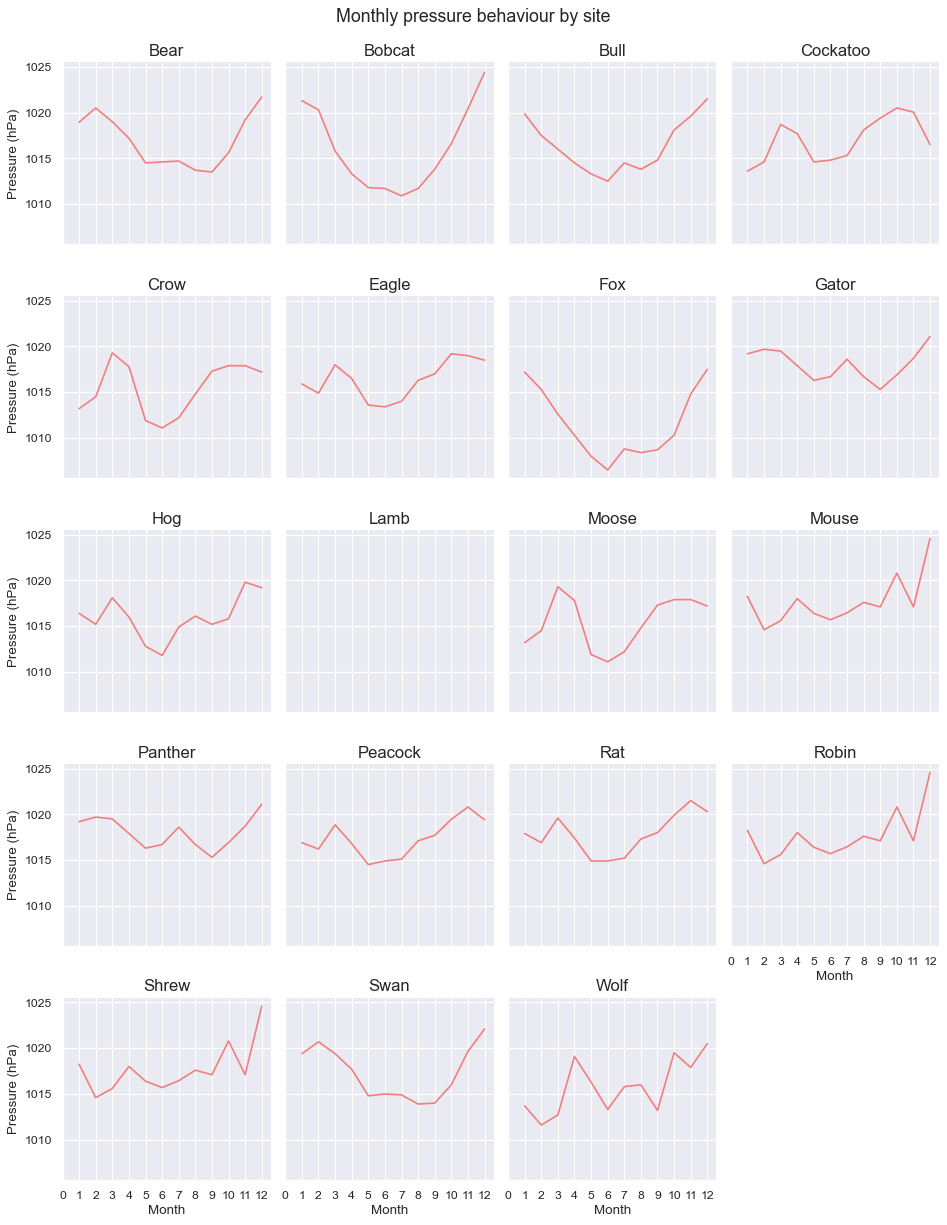

In [17]:
# Creates a temporal dataframe grouped by site and month
temp = pd.DataFrame(weather.groupby(["site_id", times.month])["seaLvlPressure"].median()).reset_index()
# All the plots in a grid
g = sns.FacetGrid(temp, col="site_id", col_wrap=4)
g.map(plt.plot, "timestamp", "seaLvlPressure", color=colors[0])
# Title of each plot
g.set_titles("{col_name}", size=15)
# Axis labels
g.set_axis_labels(x_var="Month", y_var="Pressure (hPa)")
g.set(xticks=range(13))
# Figure title
plt.suptitle('Monthly pressure behaviour by site', y=1.02, fontsize=16)

Text(0.5, 1.02, 'Monthly wind speed behaviour by site')

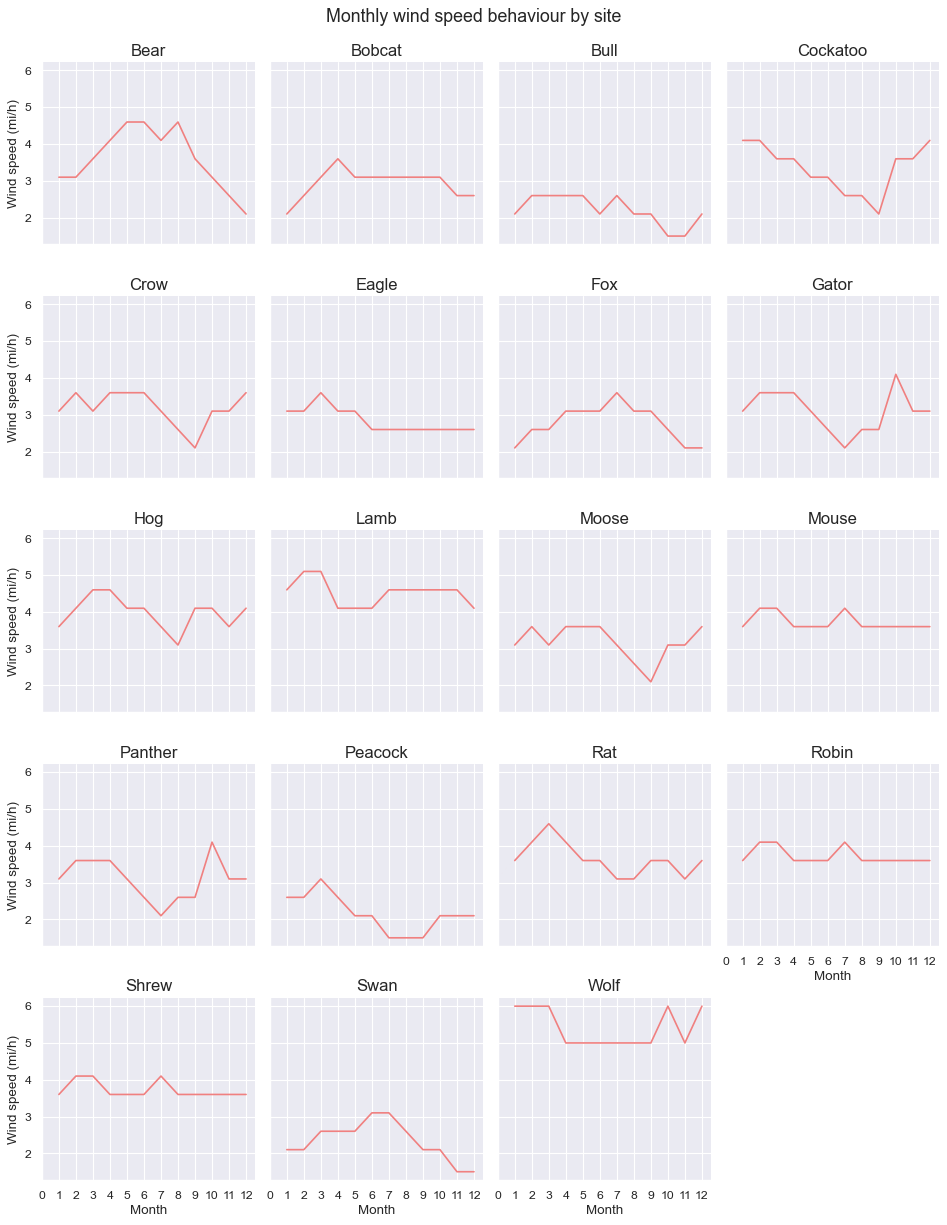

In [18]:
# Creates a temporal dataframe grouped by site and month
temp = pd.DataFrame(weather.groupby(["site_id", times.month])["windSpeed"].median()).reset_index()
# All the plots in a grid
g = sns.FacetGrid(temp, col="site_id", col_wrap=4)
g.map(plt.plot, "timestamp", "windSpeed", color=colors[0])
# Title of each plot
g.set_titles("{col_name}", size=15)
# Axis labels
g.set_axis_labels(x_var="Month", y_var="Wind speed (mi/h)")
g.set(xticks=range(13))
# Figure title
plt.suptitle('Monthly wind speed behaviour by site', y=1.02, fontsize=16)

# Comparing 2016/2017

/var/folders/rn/tvl6wp8n0tl7g97k8yjmlkpr0000gn/T/ipykernel_38882/499134949.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  g0 = sns.distplot(weather2016["airTemperature"].dropna(), ax=ax0, hist=False, color = colors[0])
/var/folders/rn/tvl6wp8n0tl7g97k8yjmlkpr0000gn/T/ipykernel_38882/499134949.py:12: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github

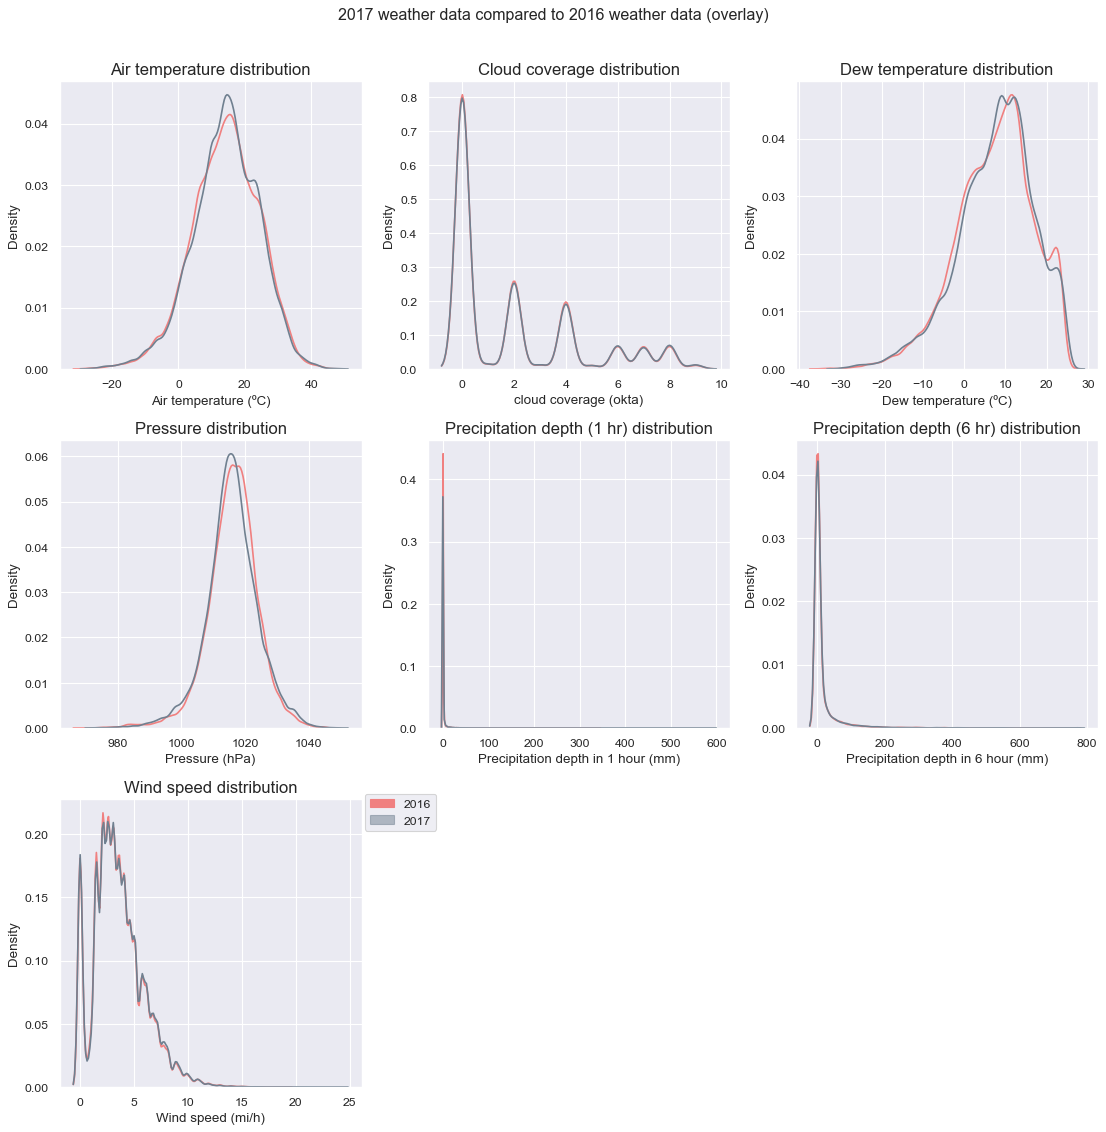

In [22]:
weather2016 = weather[weather["timestamp"] < "2017-01-01 00:00:00"]
weather2017 = weather[weather["timestamp"] >= "2017-01-01 00:00:00"]

sns.set(rc={'figure.figsize':(14,14)})
#sns.set(font_scale = 1)
f, axes = plt.subplots(3, 3)
axes = axes.flatten()

# "airTemperature" histogram
ax0 = axes[0]
g0 = sns.distplot(weather2016["airTemperature"].dropna(), ax=ax0, hist=False, color = colors[0])
g0b = sns.distplot(weather2017["airTemperature"].dropna(), ax=ax0, hist=False, color = colors[1])
ax0.title.set_text('Air temperature distribution')
ax0.set(xlabel="Air temperature (ºC)")

# "cloudCoverage" histogram
ax1 = axes[1]
g1 = sns.distplot(weather2016["cloudCoverage"].dropna(), ax=ax1, hist=False, color = colors[0])
g1b = sns.distplot(weather2017["cloudCoverage"].dropna(), ax=ax1, hist=False, color = colors[1])
ax1.title.set_text('Cloud coverage distribution')
ax1.set(xlabel="cloud coverage (okta)")

# "dewTemperature" histogram
ax2 = axes[2]
g2 = sns.distplot(weather2016["dewTemperature"].dropna(), ax=ax2, hist=False, color = colors[0])
g2b = sns.distplot(weather2017["dewTemperature"].dropna(), ax=ax2, hist=False, color = colors[1])
ax2.title.set_text('Dew temperature distribution')
ax2.set(xlabel="Dew temperature (ºC)")

# "seaLvlPressure" histogram
ax3 = axes[3]
g3 = sns.distplot(weather2016["seaLvlPressure"].dropna(), ax=ax3, hist=False, color = colors[0])
g3b = sns.distplot(weather2017["seaLvlPressure"].dropna(), ax=ax3, hist=False, color = colors[1])
ax3.title.set_text('Pressure distribution')
ax3.set(xlabel="Pressure (hPa)")

# "precipDepth1HR" histogram
ax4 = axes[4]
g4 = sns.distplot(weather2016["precipDepth1HR"].dropna(), ax=ax4, hist=False, color = colors[0], kde_kws={'bw':0.1})
g4b = sns.distplot(weather2017["precipDepth1HR"].dropna(), ax=ax4, hist=False, color = colors[1], kde_kws={'bw':0.1})
ax4.title.set_text('Precipitation depth (1 hr) distribution')
ax4.set(xlabel="Precipitation depth in 1 hour (mm)")

# "precipDepth6HR" histogram
ax5 = axes[5]
g5 = sns.distplot(weather2016["precipDepth6HR"].dropna(), ax=ax5, hist=False, color = colors[0])
g5b = sns.distplot(weather2017["precipDepth6HR"].dropna(), ax=ax5, hist=False, color = colors[1])
ax5.title.set_text('Precipitation depth (6 hr) distribution')
ax5.set(xlabel="Precipitation depth in 6 hour (mm)")

# "windSpeed" histogram
ax6 = axes[6]
g6 = sns.distplot(weather2016["windSpeed"].dropna(), ax=ax6, hist=False, color = colors[0])
g6b = sns.distplot(weather2017["windSpeed"].dropna(), ax=ax6, hist=False, color = colors[1])
ax6.title.set_text('Wind speed distribution')
ax6.set(xlabel="Wind speed (mi/h)")

# Sets fontsize
for ax in axes:
    ax.title.set_size(15)

# Remove empty axes
f.delaxes(axes[7])
f.delaxes(axes[8])
    
# Customizes legend and title
green_patch = mpatches.Patch(color=colors[0], label='2016')
blue_patch = mpatches.Patch(color=colors[1], label='2017', alpha=0.5)
f.legend(handles=[green_patch, blue_patch], ncol=1,loc=[0.33, 0.266])

f.suptitle("2017 weather data compared to 2016 weather data (overlay)", x = 0.5, y = 1.01)
f.tight_layout()

We see that the weather data between the two years is generally similar so our prediction surrogate model should be able to extrapolate well between the years

# Meter Data

In [27]:
from glob import glob
# Write custom path here
path_raw = "../data/meters/raw/"
path_proc = "../data/meters/processed/"
# files in directory
files = glob(path_raw + "*.csv")

dfs = [] # empty list of the dataframes to create
for file in files: # for each file in directory
    meter_type = file.split("/")[4].split(".")[0] # meter_type to rename the value feature
    meter = pd.read_csv(file) # load the dataset
    meter = pd.melt(meter, id_vars = "timestamp", var_name = "building_id", value_name = "meter_reading") # melt dataset
    meter["meter"] = str(meter_type) # adds column with the meter type
    dfs.append(meter) # append to list
complete_data = pd.concat(dfs, axis=0, ignore_index=True) # concatenate all meter
del(dfs, meter, file, files, meter_type)

complete_data.to_csv(path_proc + "allmeters.csv", index=False)
# Converts timestamp to datetime object
complete_data["timestamp"] = pd.to_datetime(complete_data["timestamp"], format='%Y-%m-%d %H:%M:%S')
# Sums all readings per day
complete_data["timestamp"] = pd.to_datetime(
    complete_data["timestamp"],
    format="%Y-%m-%d %H:%M:%S"
)

# Sum all numeric readings per building, meter, and day
complete_data = (
    complete_data.groupby(
        ["building_id", "meter", complete_data["timestamp"].dt.date]
    )
    .sum(numeric_only=True)
    .reset_index()
)
# Reset indexes to ungroup
complete_data = complete_data.reset_index()
# export csv
complete_data.to_csv(path_proc + "allmeters_daily.csv", index=False)

In [29]:
path_meters = "../data/meters/processed/"
path_meta = "../data/metadata/"
path_weather = "../data/weather/"

metadata = pd.read_csv(path_meta + "metadata.csv")
print(metadata.info())
meters = pd.read_csv(path_meters + "allmeters.csv")
print(meters.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1636 entries, 0 to 1635
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   building_id            1636 non-null   object 
 1   site_id                1636 non-null   object 
 2   building_id_kaggle     1449 non-null   float64
 3   site_id_kaggle         1599 non-null   float64
 4   primaryspaceusage      1615 non-null   object 
 5   sub_primaryspaceusage  1615 non-null   object 
 6   sqm                    1636 non-null   float64
 7   sqft                   1636 non-null   float64
 8   lat                    1399 non-null   float64
 9   lng                    1399 non-null   float64
 10  timezone               1636 non-null   object 
 11  electricity            1578 non-null   object 
 12  hotwater               185 non-null    object 
 13  chilledwater           555 non-null    object 
 14  steam                  370 non-null    object 
 15  wate

In [30]:
# Function to reduce the DF size
def reduce_mem_usage(df, verbose=True):
    numerics = ['int16', 'int32', 'int64', 'float16', 'float32', 'float64']
    start_mem = df.memory_usage().sum() / 1024**2    
    for col in df.columns:
        col_type = df[col].dtypes
        if col_type in numerics:
            c_min = df[col].min()
            c_max = df[col].max()
            if str(col_type)[:3] == 'int':
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                    df[col] = df[col].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                    df[col] = df[col].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                    df[col] = df[col].astype(np.int32)
                elif c_min > np.iinfo(np.int64).min and c_max < np.iinfo(np.int64).max:
                    df[col] = df[col].astype(np.int64)  
            else:
                if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
                    df[col] = df[col].astype(np.float16)
                elif c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                    df[col] = df[col].astype(np.float32)
                else:
                    df[col] = df[col].astype(np.float64)    
    end_mem = df.memory_usage().sum() / 1024**2
    if verbose: print('Mem. usage decreased to {:5.2f} Mb ({:.1f}% reduction)'.format(end_mem, 100 * (start_mem - end_mem) / start_mem))
    return df

In [31]:
# Reduce memory
metadata = reduce_mem_usage(metadata)
meters = reduce_mem_usage(meters)
gc.collect()

Mem. usage decreased to  0.32 Mb (19.5% reduction)
Mem. usage decreased to 691.00 Mb (12.5% reduction)


44691

In [ ]:
# Features from buildings metadata to add to meters dataset
buildings_sel = metadata[["building_id","site_id","primaryspaceusage","timezone"]]
# Join the datasets: meter reading + building metadata
dev = meters.merge(buildings_sel, on="building_id", how = "left")
# Transform timestamp to datetime object type
dev["timestamp"] = pd.to_datetime(dev["timestamp"], format='%Y-%m-%d %H:%M:%S')
del(meters)
gc.collect()

NameError: name 'meters' is not defined

In [34]:
del(metadata,buildings_sel)
gc.collect()

506